# EDA 09 · Did it work? XGBoost on the current w1 features vs the EDA features

**Question.** Does the 20-feature set derived in notebooks 00–08 actually beat the features the current w1 pipeline produces, when both feed the same model?

**Protocol.**
- Two XGBoost models with **identical** settings. **A** uses the current w1 export (`w1/export-tabular-v5`, 108 columns). **B** uses the 20 EDA features (section 7 of notebook 08, with `expiry_month` and `payer_days` capped at 730).
- Train on `fit`, early stopping on `stop`, classification threshold chosen on `tune` (max F1). This is the same split as the w1 and w2 models.
- Evaluation on `tune` (February holdout, in time) and on the **March cohort** (`train_v2`, out of time).
- March is looked at **once**, for this comparison only. No feature or setting is changed after seeing it.

In [1]:
import sys
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
from sklearn.metrics import (average_precision_score, brier_score_loss, f1_score, log_loss,
                             precision_recall_curve, precision_score, recall_score, roc_auc_score)
from xgboost import XGBClassifier

EDA_DIR = next(p for p in (Path.cwd(), Path.cwd() / "eda") if (p / "_common.py").exists())
sys.path.insert(0, str(EDA_DIR))
import _common as C

pd.options.display.float_format = "{:,.4f}".format
FEB_CUTOFF, MAR_CUTOFF = date(2017, 1, 31), date(2017, 2, 28)
cohort = C.load_cohort()
cohort.group_by("split").len().sort("split")

split,len
str,u32
"""fit""",744699
"""stop""",124117
"""tune""",124115


## 1. Feature tables

In [2]:
def month_expiry(df, cutoff):
    first_label = (pd.Timestamp(cutoff) + pd.Timedelta(days=1)).date()
    nxt = (pd.Timestamp(first_label) + pd.offsets.MonthBegin(1)).date()
    after = (pd.Timestamp(nxt) + pd.offsets.MonthBegin(1)).date()
    e = pl.col("last_expire")
    return df.with_columns(expiry_month=pl.when(pl.col("expiry_state") == "no txn").then(pl.lit("no txn"))
        .when(e.is_null()).then(pl.lit("unknown")).when(e <= pl.lit(cutoff)).then(pl.lit("lapsed"))
        .when(e < pl.lit(nxt)).then(pl.lit("label month")).when(e < pl.lit(after)).then(pl.lit("next month"))
        .otherwise(pl.lit("later")))

def eda_features(users, cutoff, keep_methods):
    C.set_cutoff(cutoff)
    txn = C.clean_transactions(users)
    st = C.state_block(C.subscription_state(txn, users), keep_methods=keep_methods)
    df = (month_expiry(st, cutoff)
          .join(C.history_block(txn, users), on="msno")
          .join(C.listening_block(users), on="msno")
          .join(C.member_block(users), on="msno")
          .with_columns(payer_days=pl.col("payer_days").clip(upper_bound=730)))
    C.set_cutoff(FEB_CUTOFF)
    return df

# payment methods kept as their own level: learned on fit only
C.set_cutoff(FEB_CUTOFF)
fit_users = cohort.filter(pl.col("split") == "fit").select("msno", "is_churn")
fit_state = C.subscription_state(C.clean_transactions(fit_users), fit_users)
counts = fit_state.group_by("last_payment_method_id").len()
KEEP_METHODS = counts.filter((pl.col("len") >= 1000) & pl.col("last_payment_method_id").is_not_null())["last_payment_method_id"].to_list()

CAT = ["state", "expiry_month", "plan_band", "price_level", "price_type", "pm_group", "via", "profile_state", "age_band"]
NUM = ["payer_days", "n_payments", "n_lapses", "total_lapse_days", "has_logs", "days_since_last_log",
       "longest_gap", "active_days_30", "secs_30", "bd", "tenure_days"]
NEW = CAT + NUM

feb_new = eda_features(cohort.select("msno", "is_churn"), FEB_CUTOFF, KEEP_METHODS)
mar_users = pl.read_parquet(C.PARQUET_DIR / "train_v2.parquet", columns=["msno", "is_churn"])
mar_new = eda_features(mar_users, MAR_CUTOFF, KEEP_METHODS)
assert (feb_new["msno"] == cohort["msno"]).all() and (mar_new["msno"] == mar_users["msno"]).all()

old_feb = pl.read_parquet(C.WORKSHOPS_DIR / "w1" / "export-tabular-v5" / "train_feb.parquet")
old_mar = pl.read_parquet(C.WORKSHOPS_DIR / "w1" / "export-tabular-v5" / "test.parquet")
assert (old_feb["msno"] == cohort["msno"]).all() and (old_mar["msno"] == mar_users["msno"]).all()
OLD = [c for c in old_feb.columns if c not in ("msno", "is_churn")]
print(f"A (current w1): {len(OLD)} features | B (EDA): {len(NEW)} features")
print(f"February rows: {feb_new.height:,} | March rows: {mar_new.height:,}")

A (current w1): 108 features | B (EDA): 20 features
February rows: 992,931 | March rows: 970,960


## 2. Training both models

In [3]:
split = cohort["split"].to_numpy()
y_feb = cohort["is_churn"].to_numpy()
y_mar = mar_users["is_churn"].to_numpy()

LEVELS = {c: sorted(v for v in feb_new[c].unique().to_list() if v is not None) for c in CAT}

def to_pandas_new(df):
    # categoricals as integer codes (levels fixed on February; unseen or missing -> NaN), declared as 'c' below
    p = df.select(NEW).to_pandas()
    for c in CAT:
        codes = pd.Categorical(p[c].astype(object), categories=LEVELS[c]).codes.astype(float)
        codes[codes < 0] = np.nan
        p[c] = codes
    return p.astype(float)

X = {"A current w1": (old_feb.select(OLD).to_pandas().astype(float), old_mar.select(OLD).to_pandas().astype(float)),
     "B EDA features": (to_pandas_new(feb_new), to_pandas_new(mar_new))}

PARAMS = dict(n_estimators=4000, learning_rate=0.05, max_depth=6, min_child_weight=5, subsample=0.8,
              colsample_bytree=0.8, reg_lambda=1.0, tree_method="hist", eval_metric="aucpr",
              early_stopping_rounds=150, enable_categorical=True, max_cat_to_onehot=1,
              n_jobs=16, random_state=C.SEED)
models, preds = {}, {}
FEATURE_TYPES = {"A current w1": None, "B EDA features": ["c" if c in CAT else "q" for c in NEW]}
for name, (xf, xm) in X.items():
    m = XGBClassifier(**PARAMS, feature_types=FEATURE_TYPES[name])
    m.fit(xf[split == "fit"], y_feb[split == "fit"], eval_set=[(xf[split == "stop"], y_feb[split == "stop"])], verbose=False)
    models[name] = m
    preds[name] = {"tune": m.predict_proba(xf[split == "tune"])[:, 1], "march": m.predict_proba(xm)[:, 1]}
    print(f"{name}: best iteration {m.best_iteration}")

A current w1: best iteration 336


B EDA features: best iteration 342


## 3. Results

In [4]:
y_tune = y_feb[split == "tune"]
rows = []
for name in X:
    p_tune, p_mar = preds[name]["tune"], preds[name]["march"]
    prec, rec, thr = precision_recall_curve(y_tune, p_tune)
    f1 = 2 * prec * rec / np.clip(prec + rec, 1e-12, None)
    t = thr[np.argmax(f1[:-1])]
    for part, yy, pp in (("tune (Feb holdout)", y_tune, p_tune), ("March (out of time)", y_mar, p_mar)):
        yhat = (pp >= t).astype(int)
        rows.append({"model": name, "evaluated on": part, "roc_auc": roc_auc_score(yy, pp),
                     "avg_precision": average_precision_score(yy, pp), "log_loss": log_loss(yy, pp),
                     "brier": brier_score_loss(yy, pp), "threshold": t, "precision": precision_score(yy, yhat),
                     "recall": recall_score(yy, yhat), "f1": f1_score(yy, yhat)})
results = pd.DataFrame(rows).set_index(["evaluated on", "model"]).sort_index()
results

roc_auc  avg_precision  log_loss  brier  \
evaluated on        model                                                     
March (out of time) A current w1     0.8644         0.5930    0.2029 0.0542   
                    B EDA features   0.8689         0.6009    0.2031 0.0541   
tune (Feb holdout)  A current w1     0.8992         0.5959    0.1422 0.0379   
                    B EDA features   0.9009         0.6009    0.1412 0.0376   

                                    threshold  precision  recall     f1  
evaluated on        model                                                
March (out of time) A current w1       0.2899     0.6529  0.5159 0.5764  
                    B EDA features     0.2444     0.6429  0.5357 0.5844  
tune (Feb holdout)  A current w1       0.2899     0.5546  0.5670 0.5607  
                    B EDA features     0.2444     0.5287  0.6039 0.5638

In [5]:
rng = np.random.default_rng(C.SEED)
def paired_bootstrap(yy, pa, pb, n=300):
    out = {"d_auc": [], "d_ap": []}
    idx_all = np.arange(len(yy))
    for _ in range(n):
        i = rng.choice(idx_all, size=len(yy), replace=True)
        out["d_auc"].append(roc_auc_score(yy[i], pb[i]) - roc_auc_score(yy[i], pa[i]))
        out["d_ap"].append(average_precision_score(yy[i], pb[i]) - average_precision_score(yy[i], pa[i]))
    return {k: (np.mean(v), np.percentile(v, 2.5), np.percentile(v, 97.5)) for k, v in out.items()}

boot = []
for part, yy, key in (("tune (Feb holdout)", y_tune, "tune"), ("March (out of time)", y_mar, "march")):
    b = paired_bootstrap(yy, preds["A current w1"][key], preds["B EDA features"][key])
    for k, (m, lo, hi) in b.items():
        boot.append({"evaluated on": part, "difference (B - A)": k, "mean": m, "ci_95_low": lo, "ci_95_high": hi})
pd.DataFrame(boot)

,evaluated on,difference (B - A),mean,ci_95_low,ci_95_high
0,tune (Feb holdout),d_auc,0.0018,0.0006,0.0030
1,tune (Feb holdout),d_ap,0.0050,0.0022,0.0076
2,March (out of time),d_auc,0.0045,0.0039,0.0050
3,March (out of time),d_ap,0.0078,0.0069,0.0088


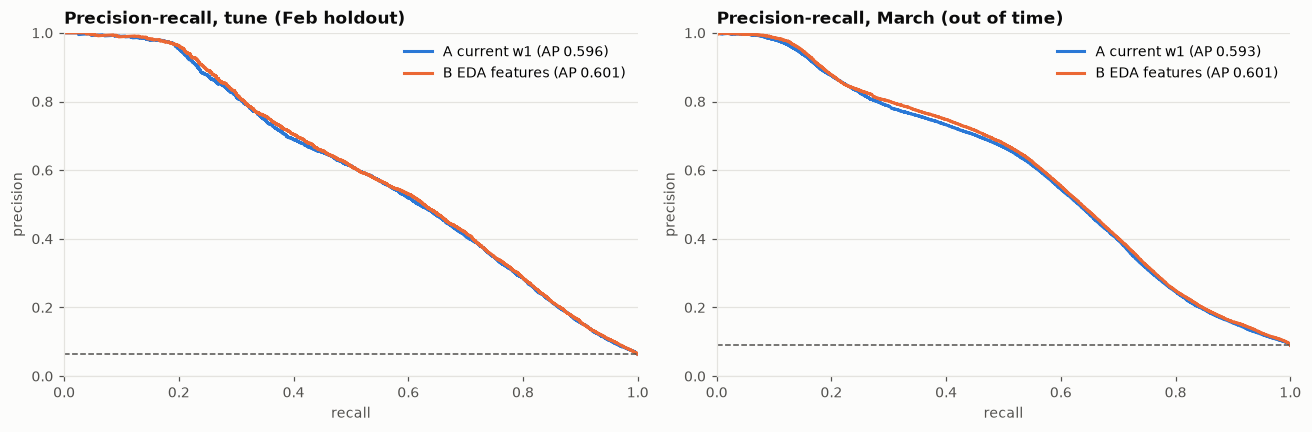

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (part, yy, key) in zip(axes, (("tune (Feb holdout)", y_tune, "tune"), ("March (out of time)", y_mar, "march"))):
    for name, color in (("A current w1", C.COLORS["stay"]), ("B EDA features", C.COLORS["churn"])):
        pr, rc, _ = precision_recall_curve(yy, preds[name][key])
        ax.plot(rc, pr, color=color, linewidth=2, label=f"{name} (AP {average_precision_score(yy, preds[name][key]):.3f})")
    ax.axhline(yy.mean(), color=C.COLORS["base"], linestyle="--", linewidth=1)
    ax.set_xlabel("recall"); ax.set_ylabel("precision"); ax.set_title(f"Precision-recall, {part}", loc="left")
    ax.legend(frameon=False); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
fig.tight_layout(); C.save_fig(fig, "09_pr_curves"); plt.show()

In [7]:
imp = pd.Series(models["B EDA features"].get_booster().get_score(importance_type="total_gain"))
imp.index = [NEW[int(k[1:])] if k.startswith("f") and k[1:].isdigit() else k for k in imp.index]
imp = imp.sort_values(ascending=False)
(imp / imp.sum()).rename("share of total gain").to_frame()

,share of total gain
state,0.4584
pm_group,0.1756
expiry_month,0.1015
payer_days,0.0349
longest_gap,0.0324
price_level,0.0294
n_payments,0.0244
active_days_30,0.0244
secs_30,0.0194
days_since_last_log,0.0180



- **B wins on every ranking metric, in both holdouts, and the paired-bootstrap intervals exclude zero:**
  - February holdout (`tune`): ROC AUC +0.0018 [0.0006, 0.0030], AP +0.0050 [0.0022, 0.0076].
  - March (out of time): ROC AUC +0.0045 [0.0039, 0.0050], AP +0.0078 [0.0069, 0.0088]. F1 at the `tune` threshold goes from 0.576 to 0.584.
- **The gap widens out of time** (AUC +0.0018 in February, +0.0045 in March): the EDA features degrade less when the cohort changes. This is consistent with the drift fixes of notebook 08 and with dropping definitions tied to file order or calendar quirks.
- **The gains are modest.** Most of the signal (the subscription state) was already in the old features, in a noisier form. The value of the new set is that it reaches slightly better results with **20 instead of 108 columns**, each one justified, and that it generalises better.
- **Log-loss and Brier on March are equal for both models.** Both are trained at a 6.4 % base rate and tested at 9.0 %, so their probabilities are miscalibrated by the same shift. That is a calibration problem (recalibrate or adjust the prior), not a feature problem.
- Importance (share of total gain in B): `state` dominates (46 %), followed by `pm_group` (18 %) and `expiry_month` (10 %). History and listening share the rest, led by `payer_days` and `longest_gap`. This is the order found by the EDA.


## 4. Conclusion


**Yes, it worked, and modestly.** With the same XGBoost and the same split, the 20 EDA features beat the 108 current w1 columns in AUC, AP and F1, on the February holdout and, by more, on the out-of-time March cohort. All differences are significant under a paired bootstrap. The model is also simpler and its features are defensible one by one.

Two things the EDA did **not** change, and that w1 still needs to handle:
- **Calibration** under the base-rate shift (6.4 % → 9.0 %).
- **Hyper-parameters**: this comparison uses one fixed configuration for both models. The w1 Optuna search should be rerun on the new table.


---
**Previous:** `08_integration_and_drift.ipynb`